# Optimisation de profit d'un atelier en utilisant QAOA

## Table des matieres

- [Exposition du probleme](#Exposition-du-probleme)
- [Translation mathematique du probleme](#Translation-mathematique-du-probleme)
- [Definition des variables](#Definition-des-variables)
- [Resolution du probleme (Recherche exhaustive)](#Resolution-du-probleme-%28Recherche-exhaustive%29)
    - [Resultat de la recherche exhaustive](#Resultat-de-la-recherche-exhaustive)
    - [Resultat de la recherche exhaustive (x2 commandes)](#Resultat-de-la-recherche-exhaustive-%28x2-commandes%29)
- [Resolution du probleme (QAOA)](#Resolution-du-probleme-%28QAOA%29)
    - [Modele mathematique](#Modele-mathematique)
    - [Optimisation Binaire Quadratique sans Contrainte (Quadratic unconstrained binary optimization / QUBO)](#Optimisation-Binaire-Quadratique-sans-Contrainte-%28Quadratic-unconstrained-binary-optimization-%2F-QUBO%29)
    - [Hamiltonien](#Hamiltonien)
    - [Boucle hybride](#Boucle-hybride)
    - [Implementation](#Implementation)
        - [Etape 1 : le QUBO](#Etape-1-:-le-QUBO)
        - [Etape 2 : le Hamiltonien](#Etape-2-:-le-Hamiltonien)
        - [Etape 3 : le circuit](#Etape-3-:-le-circuit)
        - [Etape 4 : la boucle hybride](#Etape-4-:-la-boucle-hybride)
        - [Etape 5 : echantillonner et garder la meilleure selection valide](#Etape-5-:-echantillonner-et-garder-la-meilleure-selection-valide)
    - [Benchmark de QAOA](#Benchmark-de-QAOA)
- [Interpretation des resultats](#Interpretation-des-resultats)
    - [Algorirthme classique contre Algorithme mixte](#Algorirthme-classique-contre-Algorithme-mixte)
- [Conclusion](#Conclusion)
- [Glossaire](#Glossaire)



## Exposition du probleme

Un atelier possede certaines **resources**:

- Machines
- Ouvriers
- Creneaux horraires

Un atelier doit prendre une **decision**:

- A quelles commandes repondre ? 

Un atelier a un objectif:

- Un atelier doit choisir ses commandes pour **maximiser ses profits**

Un atelier a une regle:

- Il est impossible de repondre a 2 commandes necesitant les meme resources.

## Translation mathematique du probleme

Ce probleme correspond au [Problème du stable maximum](https://fr.wikipedia.org/wiki/Probl%C3%A8me_du_stable_maximum) avec poids (**Maximum Weight Independent Set / MWIS**):

> En informatique théorique, le problème du stable maximum ou maximum independent set problem en anglais, est un problème d'optimisation qui consiste étant donné un graphe non orienté à trouver un stable de cardinal maximum, c'est-à-dire un sous-ensemble de sommets du graphe, le plus grand possible, tel que les éléments de ce sous-ensemble ne soient pas voisins.
>> https://fr.wikipedia.org/wiki/Probl%C3%A8me_du_stable_maximum

Tout les probleme MWIS sont **NP-Hard**:    
il y a $2^n$ candidats pour n commandes, puisque chaque commande peut avoir un des 2 etats booleens: acceptee ou refusee.    
Une commande sera acceptee si elle maximise le profit et ne cree pas dans de conflict.

## Definition des variables

Pour notre exemple, nous allons definir un atelier tel que:

- 4 machines
- 3 ouvriers
- 3 creneaux horraires

Qui doivent repondre a 8 commandes.

Voici les definitions du probleme en python:

In [79]:
# Tableau 1 :
# les ressources de l'atelier (nom -> type).
# Chacune a une capacité de 1 commande a la fois.
RESSOURCES: dict[str, str] = {
    "Fraiseuse CNC":      "machine",
    "Découpeuse laser":   "machine",
    "Cabine de peinture": "machine",
    "Tour":               "machine",
    "Soudeur certifié":   "ouvrier",
    "Inspecteur qualité": "ouvrier",
    "Électricien":        "ouvrier",
    "Créneau lundi":      "créneau",
    "Créneau mercredi":   "créneau",
    "Créneau vendredi":   "créneau",
}
print("Ressources:", RESSOURCES)

Ressources: {'Fraiseuse CNC': 'machine', 'Découpeuse laser': 'machine', 'Cabine de peinture': 'machine', 'Tour': 'machine', 'Soudeur certifié': 'ouvrier', 'Inspecteur qualité': 'ouvrier', 'Électricien': 'ouvrier', 'Créneau lundi': 'créneau', 'Créneau mercredi': 'créneau', 'Créneau vendredi': 'créneau'}


In [80]:
# Tableau 2 :
# La liste de profit des commandes.
# La commande n a pour profit COMMANDES[n - 1]
# Il y a autant de commande que d'element dans ce tableau.
COMMANDES: list[int] = [
    5, # Commande 1 a pour profit 5
    3,
    4,
    6,
    2,
    5,
    3,
    4
]
print(f"{len(COMMANDES)} commandes au profit:", COMMANDES)

8 commandes au profit: [5, 3, 4, 6, 2, 5, 3, 4]


In [81]:
# Tableau 3 : les conflits (ressource -> commandes qui en ont besoin).
# Deux commandes de la même ligne ne peuvent pas être acceptées ensemble.
CONFLITS: dict[str, list[int]] = {
    "Fraiseuse CNC":      [1, 2],
    "Découpeuse laser":   [3, 4],
    "Cabine de peinture": [5, 6],
    "Tour":               [7, 8],
    "Soudeur certifié":   [1, 3],
    "Inspecteur qualité": [4, 6],
    "Électricien":        [5, 7],
    "Créneau lundi":      [2, 4],
    "Créneau mercredi":   [3, 5],
    "Créneau vendredi":   [6, 8],
}

def conflits_pretty_print() -> None:
    largeur_nom: int = max(map(len, CONFLITS))
    largeur_type: int = max(map(len, RESSOURCES.values()))
    for ressource, commandes in CONFLITS.items():
        liste: str = " et ".join(f"n°{c} (profit {COMMANDES[c - 1]})" for c in commandes)
        print(f"{ressource:<{largeur_nom}}  [{RESSOURCES[ressource]:<{largeur_type}}]  ->  {liste}")

conflits_pretty_print()

Fraiseuse CNC       [machine]  ->  n°1 (profit 5) et n°2 (profit 3)
Découpeuse laser    [machine]  ->  n°3 (profit 4) et n°4 (profit 6)
Cabine de peinture  [machine]  ->  n°5 (profit 2) et n°6 (profit 5)
Tour                [machine]  ->  n°7 (profit 3) et n°8 (profit 4)
Soudeur certifié    [ouvrier]  ->  n°1 (profit 5) et n°3 (profit 4)
Inspecteur qualité  [ouvrier]  ->  n°4 (profit 6) et n°6 (profit 5)
Électricien         [ouvrier]  ->  n°5 (profit 2) et n°7 (profit 3)
Créneau lundi       [créneau]  ->  n°2 (profit 3) et n°4 (profit 6)
Créneau mercredi    [créneau]  ->  n°3 (profit 4) et n°5 (profit 2)
Créneau vendredi    [créneau]  ->  n°6 (profit 5) et n°8 (profit 4)


Ici, les verifications des donnees et la creation des `PAIRES` de conflits:

In [82]:
# Assertion des listes et des creation de la liste de conflits:
from itertools import combinations

# Vérifie que les trois tableaux parlent des mêmes ressources et commandes.
def verifier_coherence(
    ressources: dict[str, str],
    commandes: list[int],
    conflits: dict[str, list[int]],
) -> None:
    assert set(conflits) == set(ressources), "ressource inconnue ou oubliée dans CONFLITS"
    n: int = len(commandes)
    for ressource, numeros in conflits.items():
        for c in numeros:
            assert 1 <= c <= n, f"commande inconnue : {c} (ressource {ressource})"

# Retourne les paires de commandes qui ne peuvent pas être acceptées ensemble.
def calculer_paires(conflits: dict[str, list[int]]) -> list[tuple[int, int]]:
    paires: list[tuple[int, int]] = []
    for numeros in conflits.values():
        for paire in combinations(sorted(numeros), 2):
            if paire not in paires:  # évite un doublon si deux commandes partagent 2 ressources
                paires.append(paire)
    return sorted(paires)

# Retourne les ressources dont la commande c a besoin
def ressources_de_commande(c: int, conflits: dict[str, list[int]]) -> list[str]:
    return [ressource for ressource, numeros in conflits.items() if c in numeros]

# Affiche pour chaque commande son profit et ses ressources.
def afficher_commandes(commandes: list[int], conflits: dict[str, list[int]]) -> None:
    for c in range(1, len(commandes) + 1):
        besoins: str = ", ".join(ressources_de_commande(c, conflits))
        print(f"Commande {c} (profit {commandes[c - 1]}) : {besoins}")

verifier_coherence(RESSOURCES, COMMANDES, CONFLITS)
N: int = len(COMMANDES)
PAIRES: list[tuple[int, int]] = calculer_paires(CONFLITS)

afficher_commandes(COMMANDES, CONFLITS)
print(f"\n{len(PAIRES)} paires en conflit : {PAIRES}")

Commande 1 (profit 5) : Fraiseuse CNC, Soudeur certifié
Commande 2 (profit 3) : Fraiseuse CNC, Créneau lundi
Commande 3 (profit 4) : Découpeuse laser, Soudeur certifié, Créneau mercredi
Commande 4 (profit 6) : Découpeuse laser, Inspecteur qualité, Créneau lundi
Commande 5 (profit 2) : Cabine de peinture, Électricien, Créneau mercredi
Commande 6 (profit 5) : Cabine de peinture, Inspecteur qualité, Créneau vendredi
Commande 7 (profit 3) : Tour, Électricien
Commande 8 (profit 4) : Tour, Créneau vendredi

10 paires en conflit : [(1, 2), (1, 3), (2, 4), (3, 4), (3, 5), (4, 6), (5, 6), (5, 7), (6, 8), (7, 8)]


## Resolution du probleme (Recherche exhaustive)

En se basant sur les tableaux et valeurs d'exemples definis precedement, nous pouvons resoudre le probleme avec un algorithme exhaustif qui itere sur les 2^n possibilites:

In [83]:
from itertools import product
from typing import NamedTuple

class Resultat(NamedTuple):
    acceptees: list[int]  # numéros (à partir de 1) des commandes acceptées
    profit: int
    nb_testes: int        # choix examinés : 2^N
    nb_valides: int       # choix sans aucun conflit

# Un choix est une suite de 0 et de 1 : choix[i - 1] vaut 1 si la commande i est acceptée.
# Il est valide si aucune paire en conflit n'est acceptée en même temps.
def est_valide(choix: tuple[int, ...], paires: list[tuple[int, int]]) -> bool:
    return all(not (choix[i - 1] and choix[j - 1]) for i, j in paires)

# Somme des profits des commandes acceptées.
def calculer_profit(choix: tuple[int, ...], commandes: list[int]) -> int:
    return sum(profit for profit, accepte in zip(commandes, choix) if accepte)

# Teste les 2^N choix possibles et garde le valide qui rapporte le plus.
def recherche_exhaustive(commandes: list[int], paires: list[tuple[int, int]]) -> Resultat:
    meilleur_choix: tuple[int, ...] = (0,) * len(commandes)
    meilleur_profit: int = 0
    nb_testes: int = 0
    nb_valides: int = 0
    for choix in product((0, 1), repeat=len(commandes)):
        nb_testes += 1
        if not est_valide(choix, paires):
            continue
        nb_valides += 1
        profit: int = calculer_profit(choix, commandes)
        if profit > meilleur_profit:
            meilleur_choix, meilleur_profit = choix, profit
    acceptees: list[int] = [i + 1 for i, x in enumerate(meilleur_choix) if x]
    return Resultat(acceptees, meilleur_profit, nb_testes, nb_valides)

print("Defini:", est_valide, calculer_profit, recherche_exhaustive)

Defini: <function est_valide at 0x702aed624540> <function calculer_profit at 0x702b98281800> <function recherche_exhaustive at 0x702b98282020>


In [84]:
# Modèle et fréquence du CPU : platform.processor() ne donne souvent que l'architecture.
def modele_cpu() -> str:
    try:
        with open("/proc/cpuinfo", encoding="utf-8") as f:
            infos: dict[str, str] = {}
            for ligne in f:
                cle, _, valeur = ligne.partition(":")
                infos.setdefault(cle.strip(), valeur.strip())
        modele: str = infos.get("model name", platform.processor() or "inconnu")
        return f"{modele} @ {float(infos['cpu MHz']):.0f} MHz" if "cpu MHz" in infos else modele
    except OSError:  # pas de /proc hors Linux
        return platform.processor() or "inconnu"

# Affiche la machine et le processus qui lancent la mesure, pour pouvoir comparer les durées.
def print_running_env() -> None:
    try:
        ram_go: str = f"{os.sysconf('SC_PAGE_SIZE') * os.sysconf('SC_PHYS_PAGES') / 1024**3:.1f} Go"
    except (ValueError, OSError, AttributeError):  # indisponible hors Unix
        ram_go = "inconnue"
    try:
        cpus_utilisables: int = len(os.sched_getaffinity(0))
    except AttributeError:  # absent sous macOS / Windows
        cpus_utilisables = os.cpu_count() or 0
    print("== Benchmark ==")
    print(f"Date           : {datetime.now():%Y-%m-%d %H:%M:%S}")
    print(f"Machine        : {platform.node()} ({platform.system()} {platform.release()}, {platform.machine()})")
    print(f"Processeur     : {modele_cpu()}")
    print(f"Coeurs         : {os.cpu_count()} logiques ({cpus_utilisables} utilisables)")
    if hasattr(os, "getloadavg"):
        charge: tuple[float, float, float] = os.getloadavg()
        print(f"Charge système : {charge[0]:.2f} / {charge[1]:.2f} / {charge[2]:.2f} (1 / 5 / 15 min)")
    print(f"Mémoire        : {ram_go}")
    print(f"Python         : {platform.python_implementation()} {platform.python_version()} ({sys.executable})")
    print("===============")

print("Defini:", modele_cpu, print_running_env)

Defini: <function modele_cpu at 0x702b981c1a80> <function print_running_env at 0x702b981c19e0>


In [85]:
# Execution des fonctions de recherches exhaustives
# Avec monitoring pour pouvoir mesurer les resultats.
import os
import platform
import resource
import sys
from datetime import datetime
from time import perf_counter

# Exécute la force brute `repetitions` fois et retourne le résultat avec la durée moyenne (en secondes).
def mesurer_recherche_exhaustive(
    commandes: list[int], paires: list[tuple[int, int]], repetitions: int
) -> tuple[Resultat, float]:
    assert repetitions >= 1, "repetitions doit être au moins 1"
    durees: list[float] = []
    for _ in range(repetitions):
        debut: float = perf_counter()
        resultat: Resultat = recherche_exhaustive(commandes, paires)
        durees.append(perf_counter() - debut)
    return resultat, sum(durees) / repetitions

def print_variables_in_use(commandes: list[int], paires: list[tuple[int, int]]):
    print("== Variables ==")
    print(f"{len(RESSOURCES)} ressources: {RESSOURCES}")
    print(f"Profits des {len(commandes)} commandes: {commandes}")
    print(f"Paires des {len(paires)} conflits: {paires}")
    print("===============")

# Retourne l'usage CPU moyen par exécution : temps réel, CPU et changements de contexte divisés par `repetitions`.
# Les informations de benchmark de la marchine servent
# a prouver que les resultats de
# l'algorithme classique de recherche exhaustive et l'algothorithme quantique de ????? sont bases sur le meme systeme.
def mesurer_avec_usage_cpu(
    commandes: list[int], paires: list[tuple[int, int]], repetitions: int, display: bool
) -> tuple[Resultat, float, dict[str, float]]:
    print_variables_in_use(commandes, paires)
    avant = resource.getrusage(resource.RUSAGE_SELF)
    debut: float = perf_counter()
    resultat, duree_moyenne = mesurer_recherche_exhaustive(commandes, paires, repetitions)
    reel: float = perf_counter() - debut
    apres = resource.getrusage(resource.RUSAGE_SELF)
    utilisateur: float = apres.ru_utime - avant.ru_utime
    systeme: float = apres.ru_stime - avant.ru_stime
    usage: dict[str, float] = {
        "reel": reel / repetitions,
        "utilisateur": utilisateur / repetitions,
        "systeme": systeme / repetitions,
        "taux_cpu": 100 * (utilisateur + systeme) / reel,  # rapport de cumuls, identique à la moyenne
        "pic_memoire_mo": apres.ru_maxrss / 1024,  # pic global : un maximum ne se moyenne pas
        "ctx_volontaires": (apres.ru_nvcsw - avant.ru_nvcsw) / repetitions,
        "ctx_forces": (apres.ru_nivcsw - avant.ru_nivcsw) / repetitions,
    }
    if display:
        print(f"Durée moyenne sur {repetitions} exécutions : {duree_moyenne * 1000:.3f} ms")
        print(f"{resultat.nb_testes} possibilités testées par exécution")
        print(f"{resultat.nb_valides} resultats valides ({resultat.nb_valides / resultat.nb_testes}%)")
        print(f"Meilleure sélection : commandes {resultat.acceptees}, profit {resultat.profit}")
        print(f"Temps réel moyen : {usage['reel'] * 1000:.3f} ms")
        print(f"Temps CPU moyen  : {usage['utilisateur'] * 1000:.3f} ms utilisateur + {usage['systeme'] * 1000:.3f} ms système ({usage['taux_cpu']:.0f} % d'un coeur)")
        print(f"Pic de mémoire   : {usage['pic_memoire_mo']:.1f} Mo")
        print(f"Changements de contexte moyens : {usage['ctx_volontaires']:.4f} volontaires, {usage['ctx_forces']:.4f} forcés par exécution")
    return resultat, duree_moyenne, usage

repetitions=10000
print_running_env()
resultat, duree_moyenne, usage = mesurer_avec_usage_cpu(COMMANDES, PAIRES, repetitions=repetitions, display=True)
resultat_exhaustif_exemple : Resultat = resultat # Sauvegarde sous nom explicit pour reutiliser plus tard


== Benchmark ==
Date           : 2026-11-24 15:52:19
Machine        : RulianPC (Linux 6.18.33.2-microsoft-standard-WSL2, x86_64)
Processeur     : Intel(R) Core(TM) Ultra 7 155H @ 2995 MHz
Coeurs         : 22 logiques (22 utilisables)
Charge système : 0.58 / 0.78 / 2.24 (1 / 5 / 15 min)
Mémoire        : 14.6 Go
Python         : CPython 3.12.13 (/home/julian/Quantum-Computing/.venv/bin/python)
== Variables ==
10 ressources: {'Fraiseuse CNC': 'machine', 'Découpeuse laser': 'machine', 'Cabine de peinture': 'machine', 'Tour': 'machine', 'Soudeur certifié': 'ouvrier', 'Inspecteur qualité': 'ouvrier', 'Électricien': 'ouvrier', 'Créneau lundi': 'créneau', 'Créneau mercredi': 'créneau', 'Créneau vendredi': 'créneau'}
Profits des 8 commandes: [5, 3, 4, 6, 2, 5, 3, 4]
Paires des 10 conflits: [(1, 2), (1, 3), (2, 4), (3, 4), (3, 5), (4, 6), (5, 6), (5, 7), (6, 8), (7, 8)]


Durée moyenne sur 10000 exécutions : 0.409 ms
256 possibilités testées par exécution
41 resultats valides (0.16015625%)
Meilleure sélection : commandes [1, 4, 5, 8], profit 17
Temps réel moyen : 0.410 ms
Temps CPU moyen  : 0.395 ms utilisateur + 0.001 ms système (97 % d'un coeur)
Pic de mémoire   : 679.9 Mo
Changements de contexte moyens : 0.0046 volontaires, 0.0019 forcés par exécution


### Resultat de la recherche exhaustive

Nous utiliserons ces resultats, obtenu sur mon PC portable, pour comparer avec QAOA:    

```
== Benchmark ==
Date           : 2026-11-24 13:50:01
Machine        : RulianPC (Linux 6.18.33.2-microsoft-standard-WSL2, x86_64)
Processeur     : Intel(R) Core(TM) Ultra 7 155H @ 2995 MHz
Coeurs         : 22 logiques (22 utilisables)
Charge système : 1.49 / 0.86 / 0.60 (1 / 5 / 15 min)
Mémoire        : 14.6 Go
Python         : CPython 3.12.13 (/home/julian/Quantum-Computing/.venv/bin/python)
===============
== Variables ==
10 ressources: {'Fraiseuse CNC': 'machine', 'Découpeuse laser': 'machine', 'Cabine de peinture': 'machine', 'Tour': 'machine', 'Soudeur certifié': 'ouvrier', 'Inspecteur qualité': 'ouvrier', 'Électricien': 'ouvrier', 'Créneau lundi': 'créneau', 'Créneau mercredi': 'créneau', 'Créneau vendredi': 'créneau'}
Profits des 8 commandes: [5, 3, 4, 6, 2, 5, 3, 4]
Paires des 10 conflits: [(1, 2), (1, 3), (2, 4), (3, 4), (3, 5), (4, 6), (5, 6), (5, 7), (6, 8), (7, 8)]
===============
Durée moyenne sur 10000 exécutions : 0.356 ms
256 possibilités testées par exécution
41 resultats valides (0.16015625%)
Meilleure sélection : commandes [1, 4, 5, 8], profit 17
Temps réel moyen : 0.356 ms
Temps CPU moyen  : 0.345 ms utilisateur + 0.000 ms système (97 % d'un coeur)
Pic de mémoire   : 270.9 Mo
Changements de contexte moyens : 0.0033 volontaires, 0.0021 forcés par exécution
```

Essayons maintenant avec 2 commandes:

### Resultat de la recherche exhaustive (x2 commandes)

In [ ]:
# Atelier agrandi : on juxtapose `facteur` copies de l'atelier de base (ressources et commandes renumérotées).
def agrandir_atelier(facteur: int) -> tuple[dict[str, str], list[int], list[tuple[int, int]]]:
    ressources: dict[str, str] = {f"{nom} #{k + 1}": t for k in range(facteur) for nom, t in RESSOURCES.items()}
    commandes: list[int] = COMMANDES * facteur
    conflits: dict[str, list[int]] = {
        f"{nom} #{k + 1}": [c + k * len(COMMANDES) for c in numeros]
        for k in range(facteur)
        for nom, numeros in CONFLITS.items()
    }
    verifier_coherence(ressources, commandes, conflits)
    return ressources, commandes, calculer_paires(conflits)

# Lance et affiche le benchmark de la force brute sur l'atelier agrandi `facteur` fois.
def benchmark_atelier(facteur: int, repetitions: int) -> None:
    _, commandes, paires = agrandir_atelier(facteur)
    print(f"== Atelier x{facteur} : {len(commandes)} commandes, {len(paires)} paires en conflit ==")
    print_running_env()
    resultat, duree_moyenne, usage = mesurer_avec_usage_cpu(commandes, paires, repetitions, True)
    print(f"Durée moyenne sur {repetitions} exécutions : {duree_moyenne * 1000:.3f} ms")
    print(f"{resultat.nb_testes} possibilités testées par exécution")
    print(f"{resultat.nb_valides} resultats valides ({100 * resultat.nb_valides / resultat.nb_testes:.5f} %)")
    print(f"Meilleure sélection : commandes {resultat.acceptees}, profit {resultat.profit}")
    print(f"Temps CPU moyen  : {usage['utilisateur'] * 1000:.3f} ms utilisateur + {usage['systeme'] * 1000:.3f} ms système ({usage['taux_cpu']:.0f} % d'un coeur)")
    print(f"Pic de mémoire   : {usage['pic_memoire_mo']:.1f} Mo")

benchmark_atelier(facteur=2, repetitions=10000)

== Atelier x2 : 16 commandes, 20 paires en conflit ==
== Benchmark ==
Date           : 2026-11-24 15:52:23
Machine        : RulianPC (Linux 6.18.33.2-microsoft-standard-WSL2, x86_64)
Processeur     : Intel(R) Core(TM) Ultra 7 155H @ 2995 MHz
Coeurs         : 22 logiques (22 utilisables)
Charge système : 0.69 / 0.80 / 2.23 (1 / 5 / 15 min)
Mémoire        : 14.6 Go
Python         : CPython 3.12.13 (/home/julian/Quantum-Computing/.venv/bin/python)
== Variables ==
10 ressources: {'Fraiseuse CNC': 'machine', 'Découpeuse laser': 'machine', 'Cabine de peinture': 'machine', 'Tour': 'machine', 'Soudeur certifié': 'ouvrier', 'Inspecteur qualité': 'ouvrier', 'Électricien': 'ouvrier', 'Créneau lundi': 'créneau', 'Créneau mercredi': 'créneau', 'Créneau vendredi': 'créneau'}
Profits des 16 commandes: [5, 3, 4, 6, 2, 5, 3, 4, 5, 3, 4, 6, 2, 5, 3, 4]
Paires des 20 conflits: [(1, 2), (1, 3), (2, 4), (3, 4), (3, 5), (4, 6), (5, 6), (5, 7), (6, 8), (7, 8), (9, 10), (9, 11), (10, 12), (11, 12), (11, 13), 

En doublant la quantite de commandes et de conflits, avec le meme nombre d'iterations et de ressources, nous obtenons ces resultats:

```
== Atelier x2 : 16 commandes, 20 paires en conflit ==
== Benchmark ==
Date           : 2026-11-24 13:50:22
Machine        : RulianPC (Linux 6.18.33.2-microsoft-standard-WSL2, x86_64)
Processeur     : Intel(R) Core(TM) Ultra 7 155H @ 2995 MHz
Coeurs         : 22 logiques (22 utilisables)
Charge système : 1.36 / 0.87 / 0.61 (1 / 5 / 15 min)
Mémoire        : 14.6 Go
Python         : CPython 3.12.13 (/home/julian/Quantum-Computing/.venv/bin/python)
===============
== Variables ==
10 ressources: {'Fraiseuse CNC': 'machine', 'Découpeuse laser': 'machine', 'Cabine de peinture': 'machine', 'Tour': 'machine', 'Soudeur certifié': 'ouvrier', 'Inspecteur qualité': 'ouvrier', 'Électricien': 'ouvrier', 'Créneau lundi': 'créneau', 'Créneau mercredi': 'créneau', 'Créneau vendredi': 'créneau'}
Profits des 16 commandes: [5, 3, 4, 6, 2, 5, 3, 4, 5, 3, 4, 6, 2, 5, 3, 4]
Paires des 20 conflits: [(1, 2), (1, 3), (2, 4), (3, 4), (3, 5), (4, 6), (5, 6), (5, 7), (6, 8), (7, 8), (9, 10), (9, 11), (10, 12), (11, 12), (11, 13), (12, 14), (13, 14), (13, 15), (14, 16), (15, 16)]
===============
Durée moyenne sur 10000 exécutions : 62.806 ms
65536 possibilités testées par exécution
1681 resultats valides (0.0256500244140625%)
Meilleure sélection : commandes [1, 4, 5, 8, 9, 12, 13, 16], profit 34
Temps réel moyen : 62.807 ms
Temps CPU moyen  : 60.910 ms utilisateur + 0.003 ms système (97 % d'un coeur)
Pic de mémoire   : 270.9 Mo
Changements de contexte moyens : 0.0378 volontaires, 0.3592 forcés par exécution
Durée moyenne sur 10000 exécutions : 62.806 ms
65536 possibilités testées par exécution
1681 resultats valides (2.56500 %)
Meilleure sélection : commandes [1, 4, 5, 8, 9, 12, 13, 16], profit 34
Temps CPU moyen  : 60.910 ms utilisateur + 0.003 ms système (97 % d'un coeur)
Pic de mémoire   : 270.9 Mo
```

Creeons des graphes pour afficher et comparer les resultats: 

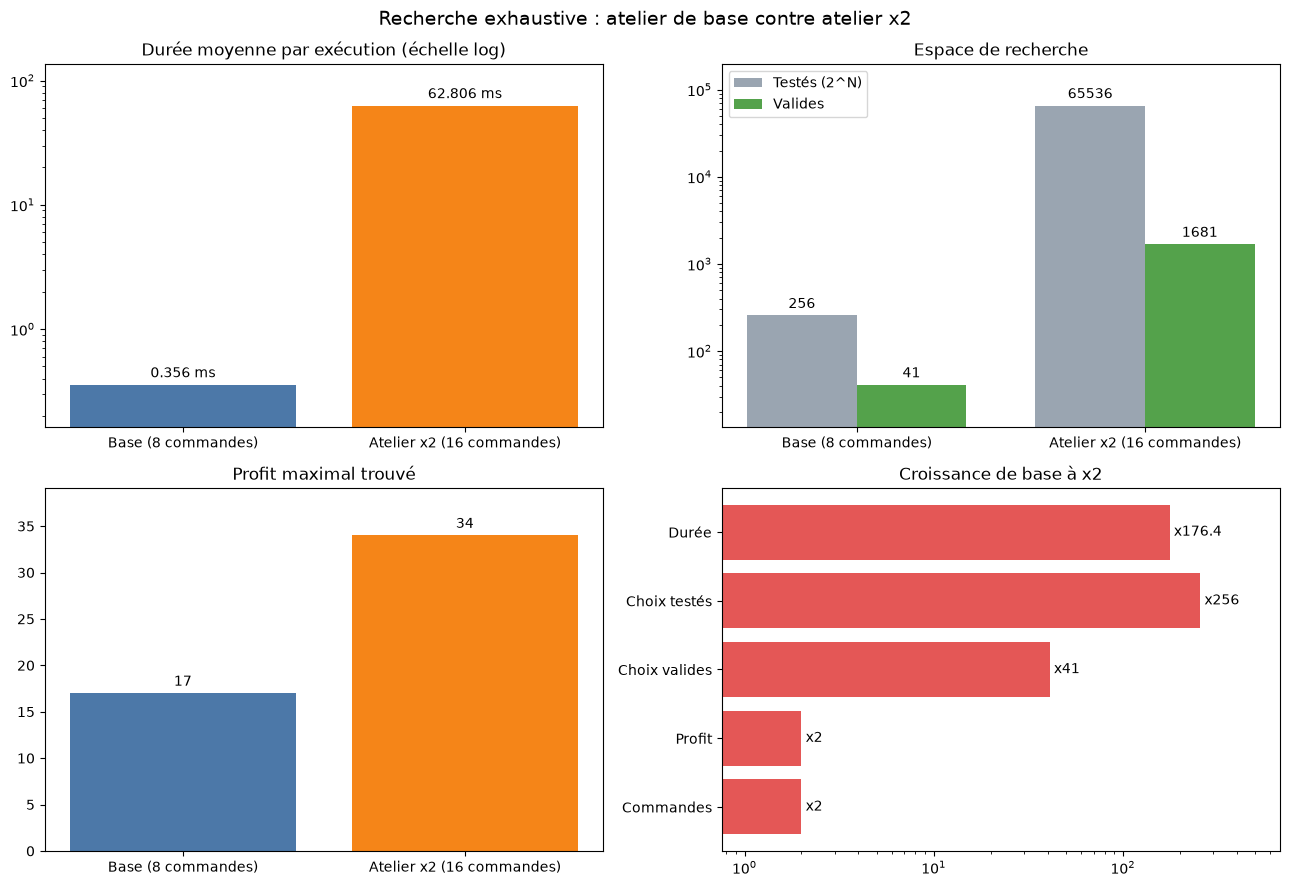

In [ ]:
# Graphes : comparaison de la recherche exhaustive sur l'atelier de base et sur l'atelier x2.
# Valeurs relevées dans les résultats ci-dessus (même machine, 10000 exécutions chacune).
import matplotlib.pyplot as plt

RESULTATS: dict[str, dict[str, float]] = {
    "Base (8 commandes)": {
        "commandes": 8, "testes": 256, "valides": 41,
        "profit": 17, "duree_ms": 0.356, "cpu_ms": 0.345,
    },
    "Atelier x2 (16 commandes)": {
        "commandes": 16, "testes": 65536, "valides": 1681,
        "profit": 34, "duree_ms": 62.806, "cpu_ms": 60.913,
    },
}
COULEURS: list[str] = ["#4C78A8", "#F58518"]

# Barres d'une seule métrique, une par atelier, avec la valeur écrite au-dessus.
def graphe_metrique(ax, resultats: dict[str, dict[str, float]], cle: str, titre: str, unite: str, log: bool = False) -> None:
    valeurs: list[float] = [r[cle] for r in resultats.values()]
    barres = ax.bar(list(resultats), valeurs, color=COULEURS[: len(valeurs)])
    ax.bar_label(barres, labels=[f"{v:g} {unite}".strip() for v in valeurs], padding=3)
    ax.set_title(titre)
    if log:
        ax.set_yscale("log")
    ax.margins(y=0.15)

# Choix examinés (2^N) contre choix valides, par atelier : montre que la part de valides s'effondre.
def graphe_espace_recherche(ax, resultats: dict[str, dict[str, float]]) -> None:
    noms: list[str] = list(resultats)
    x: list[int] = list(range(len(noms)))
    largeur: float = 0.38
    testes = ax.bar([i - largeur / 2 for i in x], [r["testes"] for r in resultats.values()], largeur, label="Testés (2^N)", color="#9AA5B1")
    valides = ax.bar([i + largeur / 2 for i in x], [r["valides"] for r in resultats.values()], largeur, label="Valides", color="#54A24B")
    ax.bar_label(testes, padding=3)
    ax.bar_label(valides, padding=3)
    ax.set_xticks(x, noms)
    ax.set_yscale("log")
    ax.set_title("Espace de recherche")
    ax.legend()
    ax.margins(y=0.15)

# Facteur de croissance de chaque métrique entre l'atelier de base et l'atelier x2.
def graphe_croissance(ax, base: dict[str, float], agrandi: dict[str, float]) -> None:
    metriques: dict[str, str] = {
        "commandes": "Commandes",
        "profit": "Profit",
        "valides": "Choix valides",
        "testes": "Choix testés",
        "duree_ms": "Durée",
    }
    facteurs: list[float] = [agrandi[c] / base[c] for c in metriques]
    barres = ax.barh(list(metriques.values()), facteurs, color="#E45756")
    ax.bar_label(barres, labels=[f"x{f:.4g}" for f in facteurs], padding=3)
    ax.set_xscale("log")
    ax.set_title("Croissance de base à x2")
    ax.margins(x=0.2)

# Figure de comparaison complète : les 4 graphes côte à côte.
def graphe_comparaison(resultats: dict[str, dict[str, float]]) -> None:
    base, agrandi = list(resultats.values())
    fig, axes = plt.subplots(2, 2, figsize=(13, 9))
    graphe_metrique(axes[0, 0], resultats, "duree_ms", "Durée moyenne par exécution (échelle log)", "ms", log=True)
    graphe_espace_recherche(axes[0, 1], resultats)
    graphe_metrique(axes[1, 0], resultats, "profit", "Profit maximal trouvé", "")
    graphe_croissance(axes[1, 1], base, agrandi)
    fig.suptitle("Recherche exhaustive : atelier de base contre atelier x2", fontsize=14)
    fig.tight_layout()
    plt.show()

graphe_comparaison(RESULTATS)

## Resolution du probleme (QAOA)

QAOA est un **algorithme hybride quantique-classique** : une partie quantique prepare et mesure un etat parametre, une partie classique ajuste ces parametres pour minimiser une energie. Il est adapte aux problemes d'optimisation combinatoire comme celui-ci.

### Modele mathematique

Soit $x_i \in \{0, 1\}$ la decision pour la commande $i$ ($x_i = 1$ si elle est acceptee), $p_i$ son profit et $E$ l'ensemble des paires de commandes en conflit. Le probleme s'ecrit:

$$\max_{x} \sum_{i} p_i x_i \quad \text{sous la contrainte} \quad x_i x_j = 0 \;\; \forall (i,j) \in E$$

Les contraintes sont ensuite retirees de l'objectif en les penalisant.

<details>
<summary>Developpement</summary>

- $\sum_i p_i x_i$ est le profit total: une commande rapporte $p_i$ si elle est acceptee ($x_i = 1$), rien sinon.
- Pour une paire $(i,j) \in E$, les deux commandes ne peuvent pas etre acceptees ensemble. Le produit $x_i x_j$ vaut $1$ seulement si $x_i = x_j = 1$, donc la contrainte $x_i x_j = 0$ exprime exactement cette regle.
- Avec $n = 8$ commandes, il y a $2^8 = 256$ selections possibles: c'est l'espace que la recherche exhaustive parcourt.

</details>

### Optimisation Binaire Quadratique sans Contrainte (Quadratic unconstrained binary optimization / QUBO)

On minimise la fonction suivante, ou $A$ est un coefficient de penalite:

$$f(x) = -\sum_{i} p_i x_i + A \sum_{(i,j) \in E} x_i x_j$$

Pour que les solutions avec conflit ne soient jamais optimales, il suffit de choisir $A > \max_i p_i$: violer une contrainte coute $A$ et ne rapporte jamais plus que le profit d'une seule commande. Ici $\max_i p_i = 6$, donc $A = 7$ convient. Le minimum de $f$ est alors une selection valide de profit maximal.

<details>
<summary>Developpement</summary>

**1. Selection valide.** Si aucune paire de $E$ n'est acceptee, tous les $x_i x_j$ sont nuls, donc $f(x) = -\sum_i p_i x_i$. Minimiser $f$ revient alors a maximiser le profit.

**2. Selection invalide.** Supposons qu'une paire $(i,j) \in E$ soit violee, et notons $k_j \geq 1$ le nombre de paires violees contenant $j$. Retirer la commande $j$ (passer $x_j$ de $1$ a $0$) change $f$ ainsi:

- le terme de profit augmente de $+p_j$ (on perd le profit de $j$);
- chaque paire violee contenant $j$ ne compte plus, ce qui retire $-A k_j$.

$$\Delta f = p_j - A\,k_j \leq p_j - A < 0 \quad \text{si } A > p_j$$

Donc toute selection invalide peut etre amelioree en retirant une commande. Le minimum de $f$ est donc atteint par une selection valide.

**3. Valeur de $A$.** Il faut $A > p_j$ pour tout $j$, soit $A > \max_i p_i$. Ici les profits sont $[5, 3, 4, 6, 2, 5, 3, 4]$, donc $\max_i p_i = 6$ et $A = 7$ est le plus petit entier qui convient.

</details>

### Hamiltonien

On remplace chaque $x_i$ par l'operateur de Pauli $Z_i$ grace a $x_i = \frac{1 - Z_i}{2}$. On obtient un Hamiltonien d'Ising:

$$H = \sum_{i} h_i Z_i + \sum_{(i,j) \in E} J_{ij} Z_i Z_j + C$$

avec $J_{ij} = \frac{A}{4}$, $h_i = \frac{p_i}{2} - \frac{A\, d_i}{4}$ ($d_i$ = nombre de conflits de la commande $i$) et $C = \frac{A\,|E|}{4} - \frac{1}{2}\sum_i p_i$.

L'etat fondamental de $H$ (energie minimale) correspond a la meilleure selection. QAOA prepare un etat parametre:

$$|\psi(\gamma, \beta)\rangle = U_B(\beta_p)\,U_C(\gamma_p)\cdots U_B(\beta_1)\,U_C(\gamma_1)\,|+\rangle^{\otimes n}, \qquad U_C(\gamma) = e^{-i\gamma H}, \quad U_B(\beta) = e^{-i\beta \sum_i X_i}$$

ou $p$ est la profondeur du circuit et $(\gamma, \beta)$ sont ses parametres.

<details>
<summary>Developpement du Hamiltonien</summary>

**1. Substitution.** Sur les etats de base, $Z_i$ vaut $+1$ si $x_i = 0$ et $-1$ si $x_i = 1$. D'ou $x_i = \frac{1 - Z_i}{2}$.

**2. Terme de profit.**

$$-\sum_i p_i \frac{1 - Z_i}{2} = -\sum_i \frac{p_i}{2} + \sum_i \frac{p_i}{2} Z_i$$

**3. Terme de penalite.** Pour chaque paire $(i,j) \in E$:

$$(1 - Z_i)(1 - Z_j) = 1 - Z_i - Z_j + Z_i Z_j$$

donc

$$A \sum_{(i,j) \in E} x_i x_j = \frac{A}{4} \sum_{(i,j) \in E} \left(1 - Z_i - Z_j + Z_i Z_j\right)$$

**4. Regrouper les termes lineaires.** Chaque commande $i$ apparait dans $d_i$ paires, donc $\sum_{(i,j) \in E} (Z_i + Z_j) = \sum_i d_i Z_i$. Il reste:

$$\frac{A}{4}\left(|E| - \sum_i d_i Z_i + \sum_{(i,j) \in E} Z_i Z_j\right)$$

**5. Identification.**

- $h_i = \frac{p_i}{2} - \frac{A\, d_i}{4}$
- $J_{ij} = \frac{A}{4}$
- $C = \frac{A\,|E|}{4} - \frac{1}{2}\sum_i p_i$

**6. Valeurs pour cet atelier** ($A = 7$, $|E| = 10$, $\sum_i p_i = 32$, donc $C = 1{,}5$). Le nombre de conflits $d_i$ se lit dans les paires $[(1,2),(1,3),(2,4),(3,4),(3,5),(4,6),(5,6),(5,7),(6,8),(7,8)]$:

| $i$ | $p_i$ | $d_i$ | $h_i = \frac{p_i}{2} - \frac{7 d_i}{4}$ |
|---|---|---|---|
| 1 | 5 | 2 | $-1{,}0$ |
| 2 | 3 | 2 | $-2{,}0$ |
| 3 | 4 | 3 | $-3{,}25$ |
| 4 | 6 | 3 | $-2{,}25$ |
| 5 | 2 | 3 | $-4{,}25$ |
| 6 | 5 | 3 | $-2{,}75$ |
| 7 | 3 | 2 | $-2{,}0$ |
| 8 | 4 | 2 | $-1{,}5$ |

Verification: $\sum_i d_i = 20 = 2\,|E|$.

**7. Pourquoi l'energie code le profit.** Pour un etat de base $|x\rangle$, $H|x\rangle = f(x)|x\rangle$ car la substitution est exacte. Le minimum de $H$ est donc le minimum de $f$, c'est-a-dire la selection valide de profit maximal.

**8. Circuit QAOA.** $|+\rangle = \frac{1}{\sqrt{2}}(|0\rangle + |1\rangle)$, donc $|+\rangle^{\otimes n} = \frac{1}{\sqrt{2^n}} \sum_x |x\rangle$: toutes les selections ont la meme amplitude au depart.

- $U_C(\gamma) = e^{-i\gamma H}$ est diagonal dans la base $|x\rangle$: il ajoute la phase $e^{-i\gamma f(x)}$ a chaque selection.
- $U_B(\beta) = \prod_i e^{-i\beta X_i}$ (les $X_i$ commutent), avec $e^{-i\beta X} = \cos\beta\, I - i \sin\beta\, X$. Il melange les selections en inversant des bits.

Alterner $U_C$ et $U_B$ sur $p$ couches donne l'etat $|\psi(\gamma,\beta)\rangle$.

</details>

### Boucle hybride

1. Le circuit quantique prepare $|\psi(\gamma, \beta)\rangle$, le mesure et en deduit une estimation de $\langle H \rangle$.
2. L'optimiseur classique (par exemple COBYLA) met a jour $(\gamma, \beta)$ pour faire baisser $\langle H \rangle$.
3. On repete jusqu'a convergence, puis on echantillonne le circuit final et on garde la meilleure selection **valide** trouvee.

Avec $p$ petit, la solution trouvee n'est pas forcement optimale: on la compare donc a la recherche exhaustive ci-dessus (profit 17 pour l'atelier de base, 34 pour l'atelier x2).

<details>
<summary>Developpement de la boucle hybride</summary>

**1. Valeur moyenne.** Si $\psi_x$ est l'amplitude de la selection $x$, la mesure donne $x$ avec probabilite $|\psi_x|^2$. L'energie moyenne vaut donc:

$$\langle H \rangle = \sum_x |\psi_x|^2 \, f(x)$$

**2. Estimation par echantillonnage.** Avec $N$ tirages $x^{(1)}, \dots, x^{(N)}$:

$$\langle H \rangle \approx \frac{1}{N} \sum_{s=1}^{N} f\left(x^{(s)}\right)$$

Chaque terme $Z_i$ et $Z_i Z_j$ se mesure dans la base de calcul, donc un seul type de mesure suffit.

**3. Mise a jour classique.** L'optimiseur cherche $(\gamma, \beta) = \arg\min \langle H \rangle$. Il ne voit que la valeur estimee, pas le circuit.

**4. Selection finale.** Parmi les $x^{(s)}$ mesurees, on ecarte celles qui violent une paire de $E$, puis on garde celle de profit maximal. Ce filtre est necessaire car la penalite ne garantit une solution valide qu'a l'optimum.

</details>

### Implementation

Maintenant que le modele mathematique est definie, nous pouvons l'implementer avec Qiskit et Qiskit optimization:

In [ ]:
# Dependances requises : qiskit, qiskit-optimization, scipy (voir le tutoriel d'installation).
import numpy as np
from qiskit.circuit.library import QAOAAnsatz
from qiskit.primitives import StatevectorEstimator, StatevectorSampler
from qiskit_optimization import QuadraticProgram
from scipy.optimize import minimize

print("Imported Qiskit.")

Imported Qiskit.


#### Etape 1 : le QUBO

On decrit $f(x) = -\sum_i p_i x_i + A \sum_{(i,j) \in E} x_i x_j$ dans un `QuadraticProgram`: une variable binaire par commande, le profit en terme lineaire (negatif car on minimise) et la penalite $A$ en terme quadratique.

In [ ]:
# A > max(profits) garantit qu'une selection en conflit n'est jamais optimale.
PENALITE: int = max(COMMANDES) + 1

def creer_qubo(commandes: list[int], paires: list[tuple[int, int]], penalite: int) -> QuadraticProgram:
    qp = QuadraticProgram("atelier")
    for i in range(1, len(commandes) + 1):
        qp.binary_var(f"x{i}")
    qp.minimize(
        linear={f"x{i}": -p for i, p in enumerate(commandes, start=1)},
        quadratic={(f"x{i}", f"x{j}"): penalite for i, j in paires},
    )
    return qp

QUBO: QuadraticProgram = creer_qubo(COMMANDES, PAIRES, PENALITE)
print(QUBO.prettyprint())

Problem name: atelier

Minimize
  7*x1*x2 + 7*x1*x3 + 7*x2*x4 + 7*x3*x4 + 7*x3*x5 + 7*x4*x6 + 7*x5*x6 + 7*x5*x7
  + 7*x6*x8 + 7*x7*x8 - 5*x1 - 3*x2 - 4*x3 - 6*x4 - 2*x5 - 5*x6 - 3*x7 - 4*x8

Subject to
  No constraints

  Binary variables (8)
    x1 x2 x3 x4 x5 x6 x7 x8



#### Etape 2 : le Hamiltonien

`to_ising()` applique la substitution $x_i = \frac{1 - Z_i}{2}$ vue plus haut.    
On obtient l'operateur hamiltonien $H$ (les $h_i Z_i$ et $J_{ij} Z_i Z_j$) et la constante $C$.

In [ ]:
HAMILTONIEN, CONSTANTE = QUBO.to_ising()
print(f"{HAMILTONIEN.num_qubits} qubits, {len(HAMILTONIEN)} termes, constante C = {CONSTANTE}")
print(f"Hamiltonien:\n{HAMILTONIEN}")

8 qubits, 18 termes, constante C = 1.5
Hamiltonien:
SparsePauliOp(['IIIIIIIZ', 'IIIIIIZI', 'IIIIIZII', 'IIIIZIII', 'IIIZIIII', 'IIZIIIII', 'IZIIIIII', 'ZIIIIIII', 'IIIIIIZZ', 'IIIIIZIZ', 'IIIIZIZI', 'IIIIZZII', 'IIIZIZII', 'IIZIZIII', 'IIZZIIII', 'IZIZIIII', 'ZIZIIIII', 'ZZIIIIII'],
              coeffs=[-1.  +0.j, -2.  +0.j, -3.25+0.j, -2.25+0.j, -4.25+0.j, -2.75+0.j,
 -2.  +0.j, -1.5 +0.j,  1.75+0.j,  1.75+0.j,  1.75+0.j,  1.75+0.j,
  1.75+0.j,  1.75+0.j,  1.75+0.j,  1.75+0.j,  1.75+0.j,  1.75+0.j])


#### Etape 3 : le circuit

`QAOAAnsatz` construit l'alternance $U_C(\gamma)$, $U_B(\beta)$ a partir de $H$: Hadamard sur chaque qubit (etat $|+\rangle^{\otimes n}$),    
 puis `reps` = $p$ couches. Il a $2p$ parametres: $\gamma_1, \beta_1, \dots, \gamma_p, \beta_p$.

8 qubits, 6 parametres (gamma, beta)


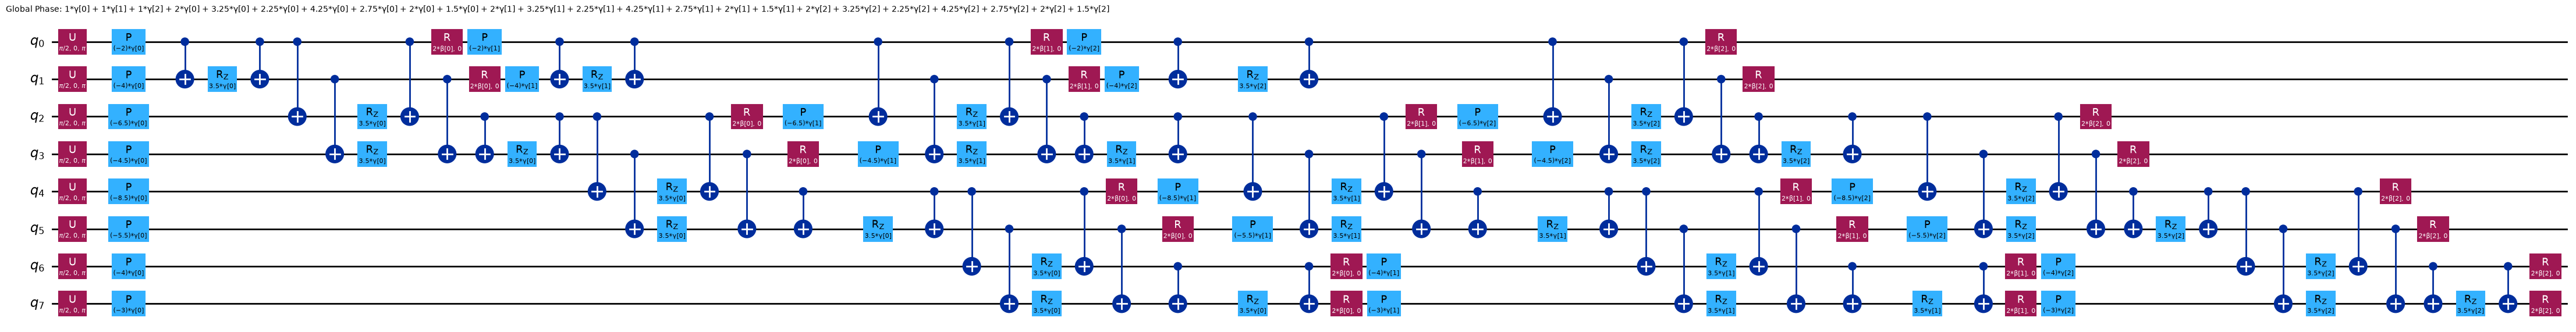

In [ ]:
PROFONDEUR: int = 3  # p : nombre de couches

# decompose() remplace PauliEvolutionGate par des portes RZZ/RX, beaucoup plus rapides a simuler.
CIRCUIT = QAOAAnsatz(HAMILTONIEN, reps=PROFONDEUR).decompose(reps=3)
print(f"{CIRCUIT.num_qubits} qubits, {CIRCUIT.num_parameters} parametres (gamma, beta)")
CIRCUIT.draw("mpl", fold=-1)

#### Etape 4 : la boucle hybride

- Partie quantique: `energie(parametres)` calcule $\langle H \rangle$ avec le circuit.     
- Partie classique: COBYLA ajuste $(\gamma, \beta)$ pour la faire baisser.    

On relance depuis plusieurs points de depart aleatoires, car le paysage d'energie a des minima locaux.

In [ ]:
ESTIMATOR = StatevectorEstimator()  # simulation exacte, sans bruit

# Energie moyenne <H> de l'etat prepare avec ces parametres.
def energie(parametres: np.ndarray) -> float:
    pub = (CIRCUIT, HAMILTONIEN, {tuple(CIRCUIT.parameters): parametres})
    return float(ESTIMATOR.run([pub]).result()[0].data["evs"])

def optimiser(nb_departs: int, seed: int = 1):
    rng = np.random.default_rng(seed)
    essais = [
        minimize(energie, rng.uniform(0, np.pi, CIRCUIT.num_parameters), method="COBYLA", options={"maxiter": 300})
        for _ in range(nb_departs)
    ]
    return min(essais, key=lambda r: r.fun)

OPTIMUM = optimiser(nb_departs=3)
print(f"Energie minimale <H> + C = {OPTIMUM.fun + CONSTANTE:.3f} (profit moyen {-(OPTIMUM.fun + CONSTANTE):.3f})")
print("Parametres (gamma, beta) :", np.round(OPTIMUM.x, 3))

Energie minimale <H> + C = -8.090 (profit moyen 8.090)
Parametres (gamma, beta) : [2.717 1.531 1.474 0.125 3.643 1.586]


#### Etape 5 : echantillonner et garder la meilleure selection valide

On mesure le circuit final 4096 fois. Qiskit ecrit les bits de droite a gauche (le qubit 0 est le dernier caractere), on inverse donc la chaine. On ecarte les selections en conflit et on garde celle de profit maximal.

In [ ]:
TIRAGES: int = 4096

def echantillonner(parametres: np.ndarray, tirages: int) -> dict[str, int]:
    circuit = CIRCUIT.copy()
    circuit.measure_all()
    sampler = StatevectorSampler(seed=1)
    pub = (circuit, {tuple(circuit.parameters): parametres})
    return sampler.run([pub], shots=tirages).result()[0].data["meas"].get_counts()

# Reutilise est_valide et calculer_profit de la recherche exhaustive.
def meilleure_selection_valide(comptes: dict[str, int]) -> tuple[list[int], int, float]:
    meilleur: tuple[int, ...] = (0,) * N
    meilleur_profit: int = 0
    nb_valides: int = 0
    for bits, n in comptes.items():
        choix: tuple[int, ...] = tuple(int(b) for b in reversed(bits))
        if not est_valide(choix, PAIRES):
            continue
        nb_valides += n
        profit: int = calculer_profit(choix, COMMANDES)
        if profit > meilleur_profit:
            meilleur, meilleur_profit = choix, profit
    acceptees: list[int] = [i + 1 for i, x in enumerate(meilleur) if x]
    return acceptees, meilleur_profit, nb_valides / sum(comptes.values())

COMPTES = echantillonner(OPTIMUM.x, TIRAGES)
acceptees, profit, part_valide = meilleure_selection_valide(COMPTES)
print(f"QAOA (p={PROFONDEUR}) : commandes {acceptees}, profit {profit}")
print(f"{100 * part_valide:.1f} % des tirages sont valides")
print(f"Precedente recherche exhaustive : commandes {resultat_exhaustif_exemple.acceptees}, profit {resultat_exhaustif_exemple.profit}")

QAOA (p=3) : commandes [1, 4, 5, 8], profit 17
65.7 % des tirages sont valides
Precedente recherche exhaustive : commandes [1, 4, 5, 8], profit 17


### Benchmark de QAOA

On mesure QAOA comme la recherche exhaustive: meme machine, meme atelier (base puis x2), memes indicateurs (duree, CPU, memoire, changements de contexte).    
La mesure couvre toute la chaine: QUBO, Hamiltonien, circuit, optimisation COBYLA et echantillonnage.

QAOA est stochastique: chaque repetition utilise une graine differente et on releve **combien de fois l'optimum est trouve**.    
Il y a moins de repetitions que pour la force brute, car une execution dure plusieurs secondes.

In [ ]:
# Benchmark de QAOA : meme mesure que la recherche exhaustive, sur le meme atelier.
from statistics import stdev

class ResultatQaoa(NamedTuple):
    acceptees: list[int]
    profit: int
    nb_evaluations: int  # appels a l'estimateur, tous departs confondus
    part_valide: float   # part des tirages sans conflit

# Resout le probleme de bout en bout : QUBO, Hamiltonien, circuit, COBYLA, echantillonnage.
def resoudre_qaoa(
    commandes: list[int], paires: list[tuple[int, int]], profondeur: int, nb_departs: int, tirages: int, seed: int
) -> ResultatQaoa:
    hamiltonien, _ = creer_qubo(commandes, paires, max(commandes) + 1).to_ising()
    circuit = QAOAAnsatz(hamiltonien, reps=profondeur).decompose(reps=3)
    cles = tuple(circuit.parameters)
    estimateur = StatevectorEstimator()

    def energie_locale(parametres: np.ndarray) -> float:
        pub = (circuit, hamiltonien, {cles: parametres})
        return float(estimateur.run([pub]).result()[0].data["evs"])

    rng = np.random.default_rng(seed)
    essais = [
        minimize(energie_locale, rng.uniform(0, np.pi, circuit.num_parameters), method="COBYLA", options={"maxiter": 300})
        for _ in range(nb_departs)
    ]
    optimum = min(essais, key=lambda r: r.fun)

    mesure = circuit.copy()
    mesure.measure_all()
    pub = (mesure, {tuple(mesure.parameters): optimum.x})
    comptes: dict[str, int] = StatevectorSampler(seed=seed).run([pub], shots=tirages).result()[0].data["meas"].get_counts()

    meilleur: tuple[int, ...] = (0,) * len(commandes)
    meilleur_profit: int = 0
    nb_valides: int = 0
    for bits, n in comptes.items():
        choix = tuple(int(b) for b in reversed(bits))
        if not est_valide(choix, paires):
            continue
        nb_valides += n
        profit = calculer_profit(choix, commandes)
        if profit > meilleur_profit:
            meilleur, meilleur_profit = choix, profit
    acceptees = [i + 1 for i, x in enumerate(meilleur) if x]
    return ResultatQaoa(acceptees, meilleur_profit, sum(r.nfev for r in essais), nb_valides / tirages)

# Lance QAOA `repetitions` fois (graine differente a chaque fois) et releve les memes mesures que la force brute.
def mesurer_qaoa(
    commandes: list[int], paires: list[tuple[int, int]], repetitions: int, profondeur: int, nb_departs: int, tirages: int
) -> tuple[list[ResultatQaoa], list[float], dict[str, float]]:
    assert repetitions >= 1, "repetitions doit être au moins 1"
    resultats: list[ResultatQaoa] = []
    durees: list[float] = []
    avant = resource.getrusage(resource.RUSAGE_SELF)
    debut: float = perf_counter()
    for graine in range(repetitions):
        t: float = perf_counter()
        resultats.append(resoudre_qaoa(commandes, paires, profondeur, nb_departs, tirages, graine))
        durees.append(perf_counter() - t)
    reel: float = perf_counter() - debut
    apres = resource.getrusage(resource.RUSAGE_SELF)
    utilisateur: float = apres.ru_utime - avant.ru_utime
    systeme: float = apres.ru_stime - avant.ru_stime
    usage: dict[str, float] = {
        "utilisateur": utilisateur / repetitions,
        "systeme": systeme / repetitions,
        "taux_cpu": 100 * (utilisateur + systeme) / reel,
        "pic_memoire_mo": apres.ru_maxrss / 1024,
        "ctx_volontaires": (apres.ru_nvcsw - avant.ru_nvcsw) / repetitions,
        "ctx_forces": (apres.ru_nivcsw - avant.ru_nivcsw) / repetitions,
    }
    return resultats, durees, usage

# Affiche le benchmark de QAOA sur l'atelier agrandi `facteur` fois, a comparer a `benchmark_atelier`.
def benchmark_qaoa(facteur: int, repetitions: int, profondeur: int = PROFONDEUR, nb_departs: int = 3, tirages: int = TIRAGES) -> None:
    _, commandes, paires = agrandir_atelier(facteur)
    optimal: int = recherche_exhaustive(commandes, paires).profit
    print(f"== QAOA atelier x{facteur} : {len(commandes)} commandes ({len(commandes)} qubits), {len(paires)} paires en conflit ==")
    print_running_env()
    print_variables_in_use(commandes, paires)
    resultats, durees, usage = mesurer_qaoa(commandes, paires, repetitions, profondeur, nb_departs, tirages)
    moyenne: float = sum(durees) / repetitions
    ecart: float = stdev(durees) if repetitions > 1 else 0.0
    trouves: int = sum(r.profit == optimal for r in resultats)
    meilleur: ResultatQaoa = max(resultats, key=lambda r: r.profit)
    print(f"Durée moyenne sur {repetitions} exécutions : {moyenne * 1000:.3f} ms (écart-type {ecart * 1000:.3f} ms)")
    print(f"p={profondeur}, {nb_departs} départs COBYLA, {tirages} tirages par exécution")
    print(f"{sum(r.nb_evaluations for r in resultats) / repetitions:.0f} évaluations de l'énergie par exécution")
    print(f"{100 * sum(r.part_valide for r in resultats) / repetitions:.1f} % des tirages valides")
    print(f"Optimum trouvé {trouves}/{repetitions} fois (profit optimal {optimal})")
    print(f"Meilleure sélection : commandes {meilleur.acceptees}, profit {meilleur.profit}")
    print(f"Temps CPU moyen  : {usage['utilisateur'] * 1000:.3f} ms utilisateur + {usage['systeme'] * 1000:.3f} ms système ({usage['taux_cpu']:.0f} % d'un coeur)")
    print(f"Pic de mémoire   : {usage['pic_memoire_mo']:.1f} Mo")
    print(f"Changements de contexte moyens : {usage['ctx_volontaires']:.4f} volontaires, {usage['ctx_forces']:.4f} forcés par exécution")

print("Defini:", resoudre_qaoa, mesurer_qaoa, benchmark_qaoa)

Defini: <function resoudre_qaoa at 0x702aed92b7e0> <function mesurer_qaoa at 0x702aed92bd80> <function benchmark_qaoa at 0x702aed92bba0>


In [ ]:
# QAOA sur l'atelier
benchmark_qaoa(facteur=1, repetitions=10)

## Resultats sur ma machine:
# == QAOA atelier x1 : 8 commandes (8 qubits), 10 paires en conflit ==
# == Benchmark ==
# Date           : 2026-11-24 15:36:14
# Machine        : RulianPC (Linux 6.18.33.2-microsoft-standard-WSL2, x86_64)
# Processeur     : Intel(R) Core(TM) Ultra 7 155H @ 2995 MHz
# Coeurs         : 22 logiques (22 utilisables)
# Charge système : 8.30 / 6.89 / 5.42 (1 / 5 / 15 min)
# Mémoire        : 14.6 Go
# Python         : CPython 3.12.13 (/home/julian/Quantum-Computing/.venv/bin/python)
# ===============
# == Variables ==
# 10 ressources: {'Fraiseuse CNC': 'machine', 'Découpeuse laser': 'machine', 'Cabine de peinture': 'machine', 'Tour': 'machine', 'Soudeur certifié': 'ouvrier', 'Inspecteur qualité': 'ouvrier', 'Électricien': 'ouvrier', 'Créneau lundi': 'créneau', 'Créneau mercredi': 'créneau', 'Créneau vendredi': 'créneau'}
# Profits des 8 commandes: [5, 3, 4, 6, 2, 5, 3, 4]
# Paires des 10 conflits: [(1, 2), (1, 3), (2, 4), (3, 4), (3, 5), (4, 6), (5, 6), (5, 7), (6, 8), (7, 8)]
# ===============
# Durée moyenne sur 10 exécutions : 9446.441 ms (écart-type 1106.248 ms)
# p=3, 3 départs COBYLA, 4096 tirages par exécution
# 871 évaluations de l'énergie par exécution
# 62.9 % des tirages valides
# Optimum trouvé 8/10 fois (profit optimal 17)
# Meilleure sélection : commandes [1, 4, 5, 8], profit 17
# Temps CPU moyen  : 7284.153 ms utilisateur + 350.545 ms système (81 % d'un coeur)
# Pic de mémoire   : 679.9 Mo
# Changements de contexte moyens : 6988.0000 volontaires, 177.6000 forcés par exécution

== QAOA atelier x1 : 8 commandes (8 qubits), 10 paires en conflit ==
== Benchmark ==
Date           : 2026-11-24 15:39:49
Machine        : RulianPC (Linux 6.18.33.2-microsoft-standard-WSL2, x86_64)
Processeur     : Intel(R) Core(TM) Ultra 7 155H @ 2995 MHz
Coeurs         : 22 logiques (22 utilisables)
Charge système : 2.04 / 4.17 / 4.61 (1 / 5 / 15 min)
Mémoire        : 14.6 Go
Python         : CPython 3.12.13 (/home/julian/Quantum-Computing/.venv/bin/python)
== Variables ==
10 ressources: {'Fraiseuse CNC': 'machine', 'Découpeuse laser': 'machine', 'Cabine de peinture': 'machine', 'Tour': 'machine', 'Soudeur certifié': 'ouvrier', 'Inspecteur qualité': 'ouvrier', 'Électricien': 'ouvrier', 'Créneau lundi': 'créneau', 'Créneau mercredi': 'créneau', 'Créneau vendredi': 'créneau'}
Profits des 8 commandes: [5, 3, 4, 6, 2, 5, 3, 4]
Paires des 10 conflits: [(1, 2), (1, 3), (2, 4), (3, 4), (3, 5), (4, 6), (5, 6), (5, 7), (6, 8), (7, 8)]
Durée moyenne sur 10 exécutions : 8619.952 ms (écart-type 

In [ ]:
# QAOA sur l'atelier facteur 2
benchmark_qaoa(facteur=2, repetitions=3)

## Resultats sur ma machine:
# == QAOA atelier x2 : 16 commandes (16 qubits), 20 paires en conflit ==
# == Benchmark ==
# Date           : 2026-11-24 15:29:57
# Machine        : RulianPC (Linux 6.18.33.2-microsoft-standard-WSL2, x86_64)
# Processeur     : Intel(R) Core(TM) Ultra 7 155H @ 2995 MHz
# Coeurs         : 22 logiques (22 utilisables)
# Charge système : 1.70 / 2.94 / 3.87 (1 / 5 / 15 min)
# Mémoire        : 14.6 Go
# Python         : CPython 3.12.13 (/home/julian/Quantum-Computing/.venv/bin/python)
# ===============
# == Variables ==
# 10 ressources: {'Fraiseuse CNC': 'machine', 'Découpeuse laser': 'machine', 'Cabine de peinture': 'machine', 'Tour': 'machine', 'Soudeur certifié': 'ouvrier', 'Inspecteur qualité': 'ouvrier', 'Électricien': 'ouvrier', 'Créneau lundi': 'créneau', 'Créneau mercredi': 'créneau', 'Créneau vendredi': 'créneau'}
# Profits des 16 commandes: [5, 3, 4, 6, 2, 5, 3, 4, 5, 3, 4, 6, 2, 5, 3, 4]
# Paires des 20 conflits: [(1, 2), (1, 3), (2, 4), (3, 4), (3, 5), (4, 6), (5, 6), (5, 7), (6, 8), (7, 8), (9, 10), (9, 11), (10, 12), (11, 12), (11, 13), (12, 14), (13, 14), (13, 15), (14, 16), (15, 16)]
# ===============
# Durée moyenne sur 3 exécutions : 129988.950 ms (écart-type 3343.374 ms)
# p=3, 3 départs COBYLA, 4096 tirages par exécution
# 894 évaluations de l'énergie par exécution
# 47.0 % des tirages valides
# Optimum trouvé 3/3 fois (profit optimal 34)
# Meilleure sélection : commandes [1, 4, 5, 8, 9, 12, 13, 16], profit 34
# Temps CPU moyen  : 1000138.616 ms utilisateur + 689.521 ms système (770 % d'un coeur)
# Pic de mémoire   : 679.9 Mo
# Changements de contexte moyens : 4600.6667 volontaires, 2031.6667 forcés par exécution


== QAOA atelier x2 : 16 commandes (16 qubits), 20 paires en conflit ==
== Benchmark ==
Date           : 2026-11-24 15:29:57
Machine        : RulianPC (Linux 6.18.33.2-microsoft-standard-WSL2, x86_64)
Processeur     : Intel(R) Core(TM) Ultra 7 155H @ 2995 MHz
Coeurs         : 22 logiques (22 utilisables)
Charge système : 1.70 / 2.94 / 3.87 (1 / 5 / 15 min)
Mémoire        : 14.6 Go
Python         : CPython 3.12.13 (/home/julian/Quantum-Computing/.venv/bin/python)
== Variables ==
10 ressources: {'Fraiseuse CNC': 'machine', 'Découpeuse laser': 'machine', 'Cabine de peinture': 'machine', 'Tour': 'machine', 'Soudeur certifié': 'ouvrier', 'Inspecteur qualité': 'ouvrier', 'Électricien': 'ouvrier', 'Créneau lundi': 'créneau', 'Créneau mercredi': 'créneau', 'Créneau vendredi': 'créneau'}
Profits des 16 commandes: [5, 3, 4, 6, 2, 5, 3, 4, 5, 3, 4, 6, 2, 5, 3, 4]
Paires des 20 conflits: [(1, 2), (1, 3), (2, 4), (3, 4), (3, 5), (4, 6), (5, 6), (5, 7), (6, 8), (7, 8), (9, 10), (9, 11), (10, 12), (11

Creeons maintenant des graphes pour interpreter les resultats et les comparer:

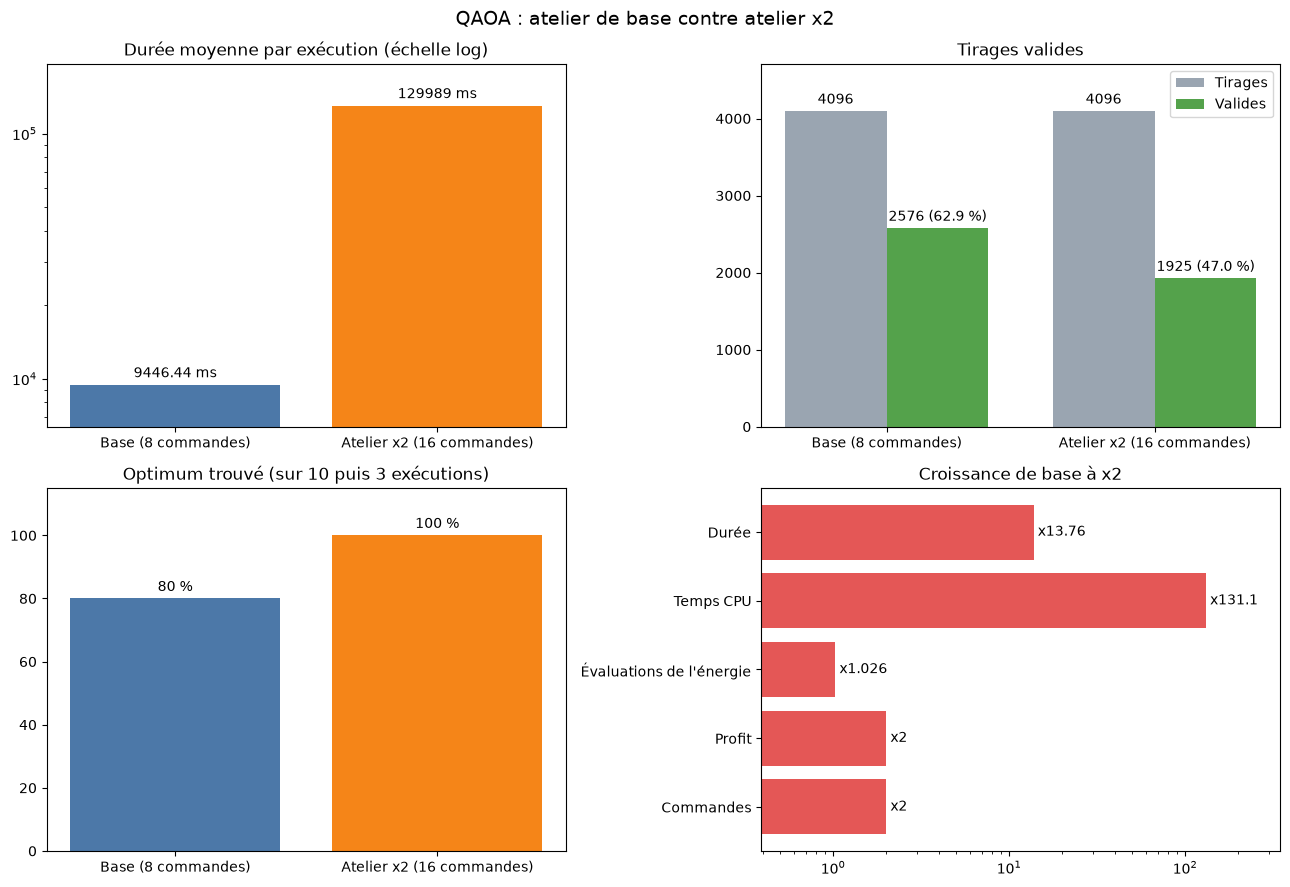

In [ ]:
# Graphes : QAOA sur l'atelier de base et sur l'atelier x2.
# Valeurs relevées dans les résultats ci-dessus (même machine). Réutilise graphe_metrique et COULEURS.
RESULTATS_QAOA: dict[str, dict[str, float]] = {
    "Base (8 commandes)": {
        "commandes": 8, "tirages": 4096, "valides": round(0.629 * 4096),
        "profit": 17, "duree_ms": 9446.441, "cpu_ms": 7284.153 + 350.545,
        "evaluations": 871, "optimum_pct": 80,
    },
    "Atelier x2 (16 commandes)": {
        "commandes": 16, "tirages": 4096, "valides": round(0.470 * 4096),
        "profit": 34, "duree_ms": 129988.950, "cpu_ms": 1000138.616 + 689.521,
        "evaluations": 894, "optimum_pct": 100,
    },
}

# Tirages mesurés contre tirages sans conflit, par atelier.
def graphe_tirages(ax, resultats: dict[str, dict[str, float]]) -> None:
    noms: list[str] = list(resultats)
    x: list[int] = list(range(len(noms)))
    largeur: float = 0.38
    tires = ax.bar([i - largeur / 2 for i in x], [r["tirages"] for r in resultats.values()], largeur, label="Tirages", color="#9AA5B1")
    valides = ax.bar([i + largeur / 2 for i in x], [r["valides"] for r in resultats.values()], largeur, label="Valides", color="#54A24B")
    ax.bar_label(tires, padding=3)
    ax.bar_label(valides, labels=[f"{r['valides']:g} ({100 * r['valides'] / r['tirages']:.1f} %)" for r in resultats.values()], padding=3)
    ax.set_xticks(x, noms)
    ax.set_title("Tirages valides")
    ax.legend()
    ax.margins(y=0.15)

# Facteur de croissance de chaque métrique entre l'atelier de base et l'atelier x2.
def graphe_croissance_qaoa(ax, base: dict[str, float], agrandi: dict[str, float]) -> None:
    metriques: dict[str, str] = {
        "commandes": "Commandes",
        "profit": "Profit",
        "evaluations": "Évaluations de l'énergie",
        "cpu_ms": "Temps CPU",
        "duree_ms": "Durée",
    }
    facteurs: list[float] = [agrandi[c] / base[c] for c in metriques]
    barres = ax.barh(list(metriques.values()), facteurs, color="#E45756")
    ax.bar_label(barres, labels=[f"x{f:.4g}" for f in facteurs], padding=3)
    ax.set_xscale("log")
    ax.set_title("Croissance de base à x2")
    ax.margins(x=0.2)

def graphe_qaoa(resultats: dict[str, dict[str, float]]) -> None:
    base, agrandi = list(resultats.values())
    fig, axes = plt.subplots(2, 2, figsize=(13, 9))
    graphe_metrique(axes[0, 0], resultats, "duree_ms", "Durée moyenne par exécution (échelle log)", "ms", log=True)
    graphe_tirages(axes[0, 1], resultats)
    graphe_metrique(axes[1, 0], resultats, "optimum_pct", "Optimum trouvé (sur 10 puis 3 exécutions)", "%")
    graphe_croissance_qaoa(axes[1, 1], base, agrandi)
    fig.suptitle("QAOA : atelier de base contre atelier x2", fontsize=14)
    fig.tight_layout()
    plt.show()

graphe_qaoa(RESULTATS_QAOA)

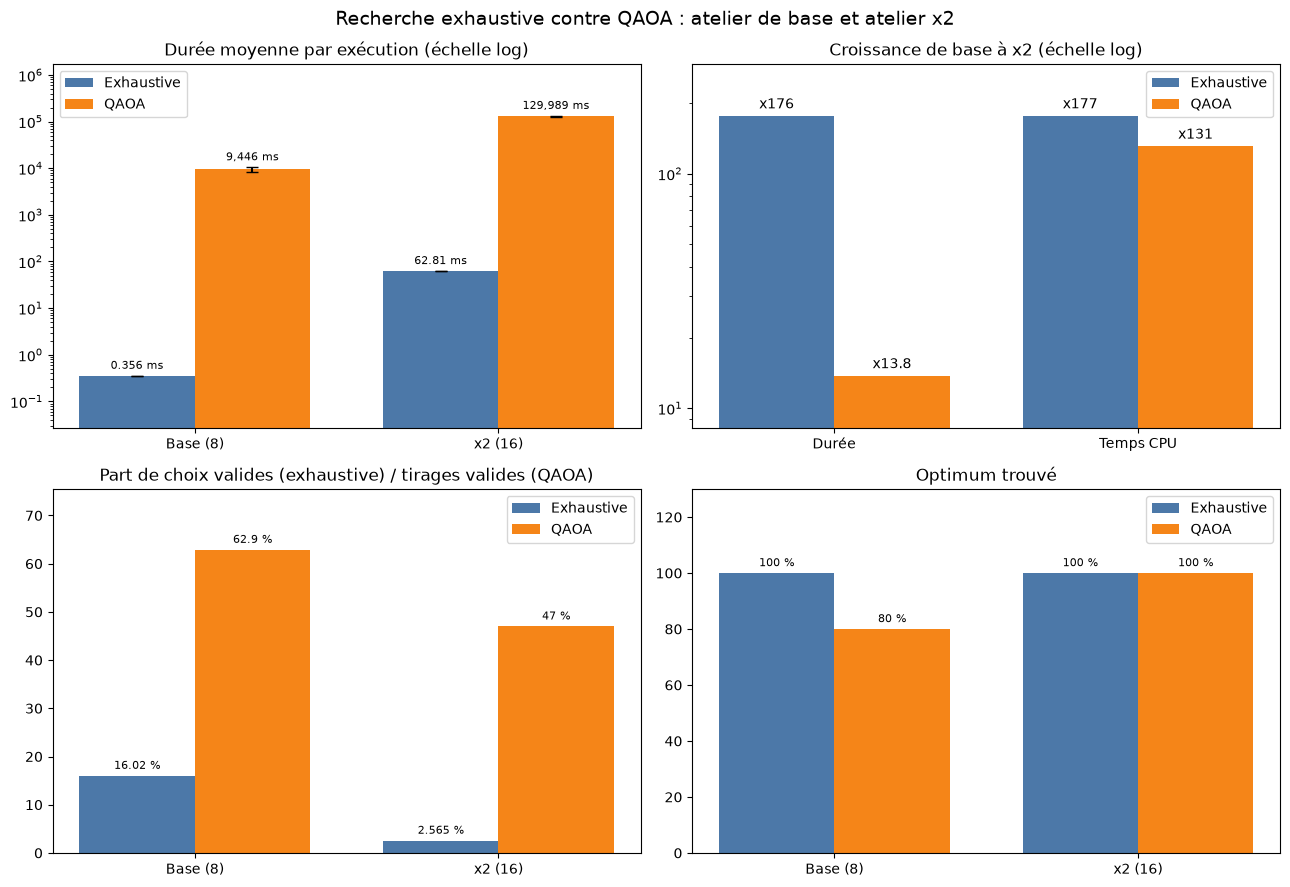

In [ ]:
# Graphes : recherche exhaustive contre QAOA, atelier de base et atelier x2.
# Valeurs relevées dans les résultats ci-dessus (même machine).
COMPARAISON: dict[str, dict[str, dict[str, float]]] = {
    "Exhaustive": {
        "Base (8)":  {"duree_ms": 0.356, "ecart_ms": 0.0, "cpu_ms": 0.345, "valide_pct": 100 * 41 / 256, "optimum_pct": 100},
        "x2 (16)":   {"duree_ms": 62.806, "ecart_ms": 0.0, "cpu_ms": 60.913, "valide_pct": 100 * 1681 / 65536, "optimum_pct": 100},
    },
    "QAOA": {
        "Base (8)":  {"duree_ms": 9446.441, "ecart_ms": 1106.248, "cpu_ms": 7284.153 + 350.545, "valide_pct": 62.9, "optimum_pct": 80},
        "x2 (16)":   {"duree_ms": 129988.950, "ecart_ms": 3343.374, "cpu_ms": 1000138.616 + 689.521, "valide_pct": 47.0, "optimum_pct": 100},
    },
}
COULEURS_ALGO: dict[str, str] = {"Exhaustive": "#4C78A8", "QAOA": "#F58518"}

# Barres groupées : un groupe par atelier, une barre par algorithme.
def barres_groupees(ax, cle: str, titre: str, unite: str, log: bool = False, erreur: str | None = None) -> None:
    ateliers: list[str] = list(next(iter(COMPARAISON.values())))
    largeur: float = 0.38
    for k, (algo, donnees) in enumerate(COMPARAISON.items()):
        x = [i + (k - 0.5) * largeur for i in range(len(ateliers))]
        valeurs: list[float] = [donnees[a][cle] for a in ateliers]
        yerr = [donnees[a][erreur] for a in ateliers] if erreur else None
        barres = ax.bar(x, valeurs, largeur, label=algo, color=COULEURS_ALGO[algo], yerr=yerr, capsize=4)
        ax.bar_label(barres, labels=[(f"{v:,.0f}" if v >= 1000 else f"{v:.4g}") + f" {unite}".rstrip() for v in valeurs], padding=3, fontsize=8)
    ax.set_xticks(range(len(ateliers)), ateliers)
    ax.set_title(titre)
    ax.legend()
    if log:
        ax.set_yscale("log")
    ax.margins(y=0.2)

# Facteur de croissance base -> x2 : QAOA grossit bien moins vite que la force brute (2^N).
def graphe_croissance_algos(ax) -> None:
    metriques: dict[str, str] = {"duree_ms": "Durée", "cpu_ms": "Temps CPU"}
    x = range(len(metriques))
    largeur: float = 0.38
    for k, (algo, donnees) in enumerate(COMPARAISON.items()):
        base, agrandi = list(donnees.values())
        facteurs: list[float] = [agrandi[m] / base[m] for m in metriques]
        barres = ax.bar([i + (k - 0.5) * largeur for i in x], facteurs, largeur, label=algo, color=COULEURS_ALGO[algo])
        ax.bar_label(barres, labels=[f"x{f:.3g}" for f in facteurs], padding=3)
    ax.set_xticks(list(x), list(metriques.values()))
    ax.set_yscale("log")
    ax.set_title("Croissance de base à x2 (échelle log)")
    ax.legend()
    ax.margins(y=0.2)

def graphe_comparaison_qaoa() -> None:
    fig, axes = plt.subplots(2, 2, figsize=(13, 9))
    barres_groupees(axes[0, 0], "duree_ms", "Durée moyenne par exécution (échelle log)", "ms", log=True, erreur="ecart_ms")
    graphe_croissance_algos(axes[0, 1])
    barres_groupees(axes[1, 0], "valide_pct", "Part de choix valides (exhaustive) / tirages valides (QAOA)", "%")
    barres_groupees(axes[1, 1], "optimum_pct", "Optimum trouvé", "%")
    axes[1, 1].set_ylim(0, 130)
    fig.suptitle("Recherche exhaustive contre QAOA : atelier de base et atelier x2", fontsize=14)
    fig.tight_layout()
    plt.show()

graphe_comparaison_qaoa()

## Interpretation des resultats

### Algorirthme classique contre Algorithme mixte

- Les resultats optimum sont similaires: les 2 algorithmes trouvent les commandes [1, 4, 5, 8] (profit 17) sur l'atelier de base et le profit 34 sur l'atelier x2.
- L'algo exhaustive est deterministe et **garantit** l'optimum. QAOA est stochastique: il l'a trouve 8 fois sur 10 (base) et 3 fois sur 3 (x2), et il faut verifier ses tirages contre les conflits.
- Seule une minorite des tirages de QAOA est valide (62.9 % puis 47.0 %), mais c'est bien plus que la part de selections valides dans l'espace de recherche (16.0 % puis 2.6 %): le circuit concentre bien la mesure sur les bonnes selections.
- Sur notre machine, l'algo exhaustive est **bien plus rapide**: 0.36 ms contre ~9 s sur 8 commandes (~26 000 fois), 63 ms contre 130 s sur 16 commandes (~2 000 fois).

### Affirmations basees sur notre exemple d'atelier 

- A 8 et 16 commandes, la force brute reste imbattable: $2^{16} = 65\,536$ candidats se testent en quelques millisecondes.
- Le cout de la force brute explose avec $n$ (x176 en doublant les commandes, proche des $2^8 = 256$ attendus), alors que celui de QAOA augmente beaucoup moins vite (x14). Le nombre d'evaluations de l'energie reste presque constant (871 puis 894).
- Ce resultat est a nuancer: QAOA est ici **simule** sur un processeur classique. Le cout de la simulation double a chaque qubit ajoute (770 % d'un coeur a 16 qubits), et COBYLA est plafonne a 300 iterations. On ne peut donc pas conclure a un avantage quantique.
- Pour que QAOA devienne interessant, il faudrait un materiel quantique reel et un atelier bien plus grand, ou la force brute n'est plus praticable. Il faudrait aussi verifier que la qualite des solutions tient quand $n$ augmente, avec une profondeur $p$ plus grande.


## Conclusion

Choisir les commandes d'un atelier sans conflit de ressources est un probleme MWIS, que l'on peut ecrire comme un QUBO puis resoudre avec QAOA.

Sur notre exemple, QAOA retrouve le meme profit optimal que la recherche exhaustive (17 sur 8 commandes, 34 sur 16), mais sans le garantir: 8 fois sur 10 sur l'atelier de base.
La force brute reste bien plus rapide, car nos ateliers sont petits et QAOA est simule sur un processeur classique.

QAOA ne montre donc **aucun avantage** ici.     
Son interet se jugerait sur un materiel quantique reel et sur un atelier assez grand pour que les $2^n$ candidats rendent la force brute impraticable.


### Execution sur une machine IBM

Pour juger QAOA sur un vrai materiel, on reutilise les angles $(\gamma, \beta)$ trouves par la simulation (`OPTIMUM.x`) et on ne fait qu'**echantillonner** le circuit sur une machine IBM. Cela evite de payer l'optimisation COBYLA en temps quantique.

- Le circuit est **transpile** vers les portes natives et la topologie de la machine choisie: sa profondeur reelle est plus grande que celle du circuit ideal.
- Le bruit de la machine fait baisser la part de tirages valides: c'est ce que l'on compare avec la simulation.
- Il faut un compte IBM Quantum enregistre une fois avec `QiskitRuntimeService.save_account(...)`, puis `EXECUTER_SUR_IBM = True`.
- Les comptes sont sauvegardes dans `results/workshop_ibm_counts.json`: les cellules suivantes se rejouent sans compte ni temps machine.

<details>
<summary><b>Tutoriel : se connecter a IBM Quantum</b></summary>

#### 1. Creer un compte
- Aller sur [quantum.cloud.ibm.com](https://quantum.cloud.ibm.com) et se connecter avec un IBMid.
- Choisir un plan. Le plan **Open** est gratuit et inclut un temps machine mensuel limite, suffisant pour un job de 8 qubits.

#### 2. Recuperer les identifiants
Depuis le tableau de bord, copier:
- la **cle API** (affichee une seule fois, a conserver);
- le **CRN de l'instance** (page *Instances*).

La cle API est un mot de passe: ne jamais la committer ni l'ecrire dans le notebook.

#### 3. Preparer l'environnement
```bash
python3 -m venv .venv
source .venv/bin/activate   # Windows : .venv\\Scripts\\activate
pip install qiskit qiskit-optimization qiskit-aer qiskit-ibm-runtime scipy networkx matplotlib pylatexenc jupyterlab
```
Python 3.10 ou plus recent est necessaire. Lancer ensuite Jupyter depuis ce meme environnement (`jupyter lab`).

#### 4. Enregistrer le compte (une seule fois, dans un terminal)
```bash
python - <<'EOF'
from qiskit_ibm_runtime import QiskitRuntimeService
QiskitRuntimeService.save_account(
    token="VOTRE_CLE_API",
    instance="VOTRE_CRN",
    channel="ibm_quantum_platform",
    overwrite=True,
)
EOF
```
Les identifiants sont ecrits dans `~/.qiskit/qiskit-ibm.json`, hors du depot. La cellule suivante les lit automatiquement.

#### 5. Tester la connexion
```bash
python -c "
from qiskit_ibm_runtime import QiskitRuntimeService
for b in QiskitRuntimeService().backends(simulator=False, operational=True):
    print(b.name, b.num_qubits, b.status().pending_jobs, 'jobs en attente')
"
```
Toute machine d'au moins 8 qubits convient.

#### 6. Lancer la cellule
Passer `EXECUTER_SUR_IBM` a `True` et executer la cellule ci-dessous. Elle attend la fin du job (la file d'attente peut durer de quelques minutes a plus). Le job est aussi visible dans *Workloads* sur le tableau de bord IBM.

#### 7. Apres l'execution
Repasser `EXECUTER_SUR_IBM` a `False` pour qu'un "tout executer" ne consomme pas de temps machine.

| Probleme | Cause probable |
|---|---|
| `Unable to find account` | `save_account` non execute, ou execute avec un autre utilisateur |
| Erreur d'authentification | Mauvaise cle, `channel` ou `instance` |
| Aucune machine listee | Le plan n'y donne pas acces, ou maintenance |
| Job longtemps en attente | Normal avec le plan Open: recuperer le resultat plus tard avec `service.job("ID_DU_JOB").result()` |

</details>

In [ ]:
# Execution sur une machine IBM (desactivee par defaut : consomme du temps machine).
import json
from pathlib import Path

EXECUTER_SUR_IBM: bool = True
FICHIER_IBM = Path("results/workshop_ibm_counts.json")

if EXECUTER_SUR_IBM:
    from qiskit.transpiler.preset_passmanagers import generate_preset_pass_manager
    from qiskit_ibm_runtime import QiskitRuntimeService, SamplerV2

    service = QiskitRuntimeService()
    machine = service.least_busy(operational=True, simulator=False, min_num_qubits=CIRCUIT.num_qubits)
    mesure = CIRCUIT.copy()
    mesure.measure_all()
    circuit_ibm = generate_preset_pass_manager(optimization_level=3, backend=machine, seed_transpiler=1).run(mesure)
    print(f"{machine.name} : profondeur {circuit_ibm.depth()} apres transpilation (circuit ideal : {mesure.depth()})")

    job = SamplerV2(mode=machine).run([(circuit_ibm, OPTIMUM.x)], shots=TIRAGES)
    print("Job soumis :", job.job_id())
    comptes_ibm = job.result()[0].data.meas.get_counts()
    FICHIER_IBM.parent.mkdir(exist_ok=True)
    FICHIER_IBM.write_text(json.dumps({
        "machine": machine.name, "job_id": job.job_id(), "tirages": TIRAGES,
        "profondeur": circuit_ibm.depth(), "parametres": list(map(float, OPTIMUM.x)), "comptes": comptes_ibm,
    }))

if FICHIER_IBM.exists():
    sauvegarde = json.loads(FICHIER_IBM.read_text())
    acceptees_ibm, profit_ibm, part_valide_ibm = meilleure_selection_valide(sauvegarde["comptes"])
    print(f"Machine {sauvegarde['machine']} (job {sauvegarde['job_id']}, profondeur {sauvegarde['profondeur']})")
    print(f"QAOA sur IBM : commandes {acceptees_ibm}, profit {profit_ibm}")
    print(f"{100 * part_valide_ibm:.1f} % des tirages valides (simulation sans bruit : {100 * part_valide:.1f} %)")
else:
    print("Pas encore de resultats IBM : passer EXECUTER_SUR_IBM a True pour les obtenir.")

Pas encore de resultats IBM : passer EXECUTER_SUR_IBM a True pour les obtenir.


## Glossaire

### Exposition du probleme et traduction mathematique

- **Ressource**: element de l'atelier (machine, ouvrier, creneau) utilisable par une seule commande a la fois.
- **Conflit**: deux commandes qui ont besoin d'une meme ressource et ne peuvent pas etre acceptees ensemble.
- **Graphe de conflits**: graphe dont les sommets sont les commandes et les aretes les conflits.
- **MWIS (Maximum Weight Independent Set)**: choisir des sommets sans voisins entre eux, avec un poids total maximal. Ici, le poids est le profit.
- **NP-Hard**: classe de problemes pour lesquels aucun algorithme rapide (polynomial) n'est connu.

### Definition des variables et recherche exhaustive

- **Recherche exhaustive (force brute)**: teste les $2^n$ selections possibles et garde la meilleure valide.
- **Selection valide**: ensemble de commandes sans aucun conflit.
- **Benchmark**: mesure repetee des performances d'un algorithme sur la meme machine.
- **Temps CPU (utilisateur / systeme)**: temps de calcul du processeur, dans le programme ou dans le noyau.
- **Pic de memoire**: memoire maximale utilisee pendant l'execution.
- **Changement de contexte**: moment ou le processeur passe a un autre processus (volontaire ou force).

### QAOA et modele mathematique

- **QAOA (Quantum Approximate Optimization Algorithm)**: algorithme hybride qui cherche une solution approchee d'un probleme d'optimisation combinatoire.
- **Algorithme hybride quantique-classique**: une partie quantique prepare et mesure un etat, une partie classique ajuste ses parametres.
- **Qubit**: unite d'information quantique, superposition de $|0\rangle$ et $|1\rangle$. Ici, un qubit par commande.
- **Superposition**: etat d'un qubit combinant $|0\rangle$ et $|1\rangle$, avec des amplitudes.
- **Amplitude**: nombre complexe dont le carre du module donne la probabilite d'une mesure.
- **Penalite ($A$)**: coefficient qui rend un conflit plus couteux que le profit qu'il rapporte.
- **QUBO (Quadratic Unconstrained Binary Optimization)**: minimisation d'une fonction quadratique de variables binaires, sans contrainte.
- **Hamiltonien**: operateur dont les valeurs propres sont les energies. Ici, il encode le cout $f(x)$.
- **Modele d'Ising**: Hamiltonien fait de termes $Z_i$ et $Z_i Z_j$.
- **Operateurs de Pauli ($X$, $Z$)**: portes a un qubit. $Z$ lit le bit (valeur propre $+1$ ou $-1$), $X$ l'inverse.
- **Etat fondamental**: etat d'energie minimale. Ici, la meilleure selection.
- **Circuit parametre**: circuit quantique dont les portes dependent de parametres reels ($\gamma$, $\beta$).
- **Profondeur ($p$)**: nombre de couches $U_C$, $U_B$ du circuit.
- **Hadamard**: porte qui met un qubit dans l'etat $|+\rangle$.
- **Valeur moyenne $\langle H \rangle$**: energie moyenne de l'etat prepare, estimee par mesures.
- **Tirage (shot)**: une mesure du circuit. On en fait plusieurs pour estimer des probabilites.
- **COBYLA**: optimiseur classique qui n'utilise pas de gradient.
- **Minimum local**: point ou l'energie est plus basse qu'autour, mais pas la plus basse possible.

### Implementation

- **Qiskit / Qiskit optimization**: bibliotheques Python pour les circuits quantiques et les problemes d'optimisation.
- **`QuadraticProgram`**: objet Qiskit qui decrit un probleme quadratique (variables, termes lineaires et quadratiques).
- **`QAOAAnsatz`**: objet Qiskit qui construit le circuit QAOA a partir d'un Hamiltonien.
- **Estimator**: primitive Qiskit qui calcule $\langle H \rangle$.
- **Sampler**: primitive Qiskit qui mesure le circuit et renvoie les comptes.
- **Simulation par vecteur d'etat**: calcul exact de l'etat quantique sur un processeur classique. Son cout double a chaque qubit.
- **Graine (seed)**: valeur qui fixe le tirage aleatoire pour reproduire un resultat.

### Interpretation des resultats

- **Deterministe / stochastique**: un algorithme deterministe donne toujours le meme resultat, un algorithme stochastique non.
- **Optimum**: meilleure solution valide, de profit maximal.
- **Avantage quantique**: cas ou un algorithme quantique resout un probleme plus vite que le meilleur algorithme classique.
